In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("Week_1_Ecommerce_Sales_Analysis.csv")
df.head()

,Order_ID,Order_Date,Customer_ID,Product_ID,Category,Subcategory,Region,City,Customer_Segment,Payment_Method,...,Gross_Sales,Discount_Amount,Sales,Cost,Shipping_Cost,Profit,Profit_Margin,Rating,Order_Status,Delivery_Date
0,ORD139897,2025-10-13 00:00:00,CUST16140,PROD1190,Home & Kitchen,Appliances,East,Owerri,Small Business,Card,...,71166.16,3558.31,67607.85,37056.58,2209.26,28342.01,0.4192,4.6,Delivered,2025-10-16 00:00:00
1,ORD132984,2025-01-22 00:00:00,CUST28769,PROD1146,Technology,Printers,South,Lagos,Consumer,Card,...,338240.48,33824.05,304416.43,182424.65,1754.18,120237.60,0.3950,4.7,Delivered,2025-01-29 00:00:00
2,ORD133816,2024-12-30 00:00:00,CUST24892,PROD1046,Office Supplies,Storage,East,Owerri,Corporate,Cash on Delivery,...,12753.20,0.00,12753.20,7720.48,3369.91,1662.81,0.1304,4.0,Delivered,2025-01-01 00:00:00
3,ORD121129,2025-03-21 00:00:00,CUST28318,PROD1172,Furniture,Shelves,Central,Minna,Consumer,Card,...,45981.72,0.00,45981.72,27640.09,2028.73,16312.89,0.3548,2.2,Delivered,2025-03-29 00:00:00
4,ORD189669,2024-10-12 00:00:00,CUST29365,PROD1078,Furniture,Chairs,East,Enugu,Small Business,Card,...,667529.45,66752.95,600776.51,296194.06,4354.22,300228.23,0.4997,3.6,Delivered,2024-10-13 00:00:00


In [3]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Delivery_Date"] = pd.to_datetime(df["Delivery_Date"], errors="coerce")

df = df.drop_duplicates().copy()

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())
print("\nSummary statistics:")
print(df.describe().round(2))

Dataset shape: (100000, 24)

Missing values:
Order_ID               0
Order_Date             0
Customer_ID            0
Product_ID             0
Category               0
Subcategory            0
Region                 0
City                1000
Customer_Segment    1000
Payment_Method      1000
Shipping_Method        0
Quantity               0
Unit_Price             0
Discount               0
Gross_Sales            0
Discount_Amount        0
Sales                  0
Cost                   0
Shipping_Cost          0
Profit                 0
Profit_Margin          0
Rating              1000
Order_Status           0
Delivery_Date          0
dtype: int64

Summary statistics:
                          Order_Date   Quantity  Unit_Price   Discount  \
count                         100000  100000.00   100000.00  100000.00   
mean   2024-12-30 12:39:59.327999744       2.94    47195.13       0.07   
min              2024-01-01 00:00:00       1.00     1565.07       0.00   
25%              2024-06-

In [4]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing_Count"] > 0]

print(missing_summary)

                  Missing_Count  Missing_Percentage
City                       1000                 1.0
Customer_Segment           1000                 1.0
Payment_Method             1000                 1.0
Rating                     1000                 1.0


In [5]:
for col in ["City", "Payment_Method", "Customer_Segment", "Rating"]:
    missing = df[col].isna()

    print(f"\n{col}")
    print("Missing rows:", missing.sum())
    print("Sales in those rows:", df.loc[missing, "Sales"].sum())
    print("Profit in those rows:", df.loc[missing, "Profit"].sum())


City
Missing rows: 1000
Sales in those rows: 126184031.23
Profit in those rows: 42310694.51

Payment_Method
Missing rows: 1000
Sales in those rows: 123887577.05000001
Profit in those rows: 40683118.77

Customer_Segment
Missing rows: 1000
Sales in those rows: 141419881.53
Profit in those rows: 44838418.379999995

Rating
Missing rows: 1000
Sales in those rows: 128724397.66999999
Profit in those rows: 42530677.03


In [6]:
for col in ["City", "Payment_Method", "Customer_Segment"]:
    df[col] = df[col].fillna("Unknown")

print(df.isna().sum())

Order_ID               0
Order_Date             0
Customer_ID            0
Product_ID             0
Category               0
Subcategory            0
Region                 0
City                   0
Customer_Segment       0
Payment_Method         0
Shipping_Method        0
Quantity               0
Unit_Price             0
Discount               0
Gross_Sales            0
Discount_Amount        0
Sales                  0
Cost                   0
Shipping_Cost          0
Profit                 0
Profit_Margin          0
Rating              1000
Order_Status           0
Delivery_Date          0
dtype: int64


In [7]:
for col in ["Rating"]:
    df[col] = df[col].fillna(df["Rating"].mean())

print(df.isna().sum())

Order_ID            0
Order_Date          0
Customer_ID         0
Product_ID          0
Category            0
Subcategory         0
Region              0
City                0
Customer_Segment    0
Payment_Method      0
Shipping_Method     0
Quantity            0
Unit_Price          0
Discount            0
Gross_Sales         0
Discount_Amount     0
Sales               0
Cost                0
Shipping_Cost       0
Profit              0
Profit_Margin       0
Rating              0
Order_Status        0
Delivery_Date       0
dtype: int64


In [8]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
profit_margin = total_profit / total_sales * 100
average_order_value = df.groupby("Order_ID")["Sales"].sum().mean()

print("OVERALL PERFORMANCE")
print(f"Total sales: {total_sales:,.2f}")
print(f"Total profit: {total_profit:,.2f}")
print(f"Total orders: {total_orders:,}")
print(f"Unique customers: {total_customers:,}")
print(f"Profit margin: {profit_margin:.2f}%")
print(f"Average order value: {average_order_value:,.2f}")

OVERALL PERFORMANCE
Total sales: 12,805,690,059.08
Total profit: 4,187,982,807.20
Total orders: 100,000
Unique customers: 19,876
Profit margin: 32.70%
Average order value: 128,056.90


In [9]:
category_analysis = (
    df.groupby("Category")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

category_analysis["Sales_Share_%"] = (
    category_analysis["Sales"] / total_sales * 100
).round(2)

print("\nCATEGORY PERFORMANCE")
print(category_analysis.round(2))



CATEGORY PERFORMANCE
                        Sales        Profit  Orders  Sales_Share_%
Category                                                          
Technology       5.594913e+09  1.895224e+09   21947          43.69
Furniture        3.494220e+09  1.170739e+09   18037          27.29
Home & Kitchen   1.814477e+09  5.745868e+08   19962          14.17
Fashion          1.001924e+09  3.059420e+08   15147           7.82
Office Supplies  9.001562e+08  2.414915e+08   24907           7.03


In [10]:
region_analysis = (
    df.groupby("Region")
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit" ,"sum"),
          Orders=("Order_ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

print("\nREGIONAL PERFORMANCE")
print(region_analysis.round(2))



REGIONAL PERFORMANCE
                Sales        Profit  Orders
Region                                     
South    3.612873e+09  1.181808e+09   27946
West     3.178552e+09  1.038863e+09   24968
East     2.323393e+09  7.592046e+08   18283
North    2.183553e+09  7.166657e+08   16813
Central  1.507319e+09  4.914414e+08   11990


In [11]:
segment_analysis = (
    df.groupby("Customer_Segment", dropna=False)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
      .sort_values("Sales", ascending=False)
)

print("\nCUSTOMER SEGMENTS")
print(segment_analysis.round(2))


CUSTOMER SEGMENTS
                         Sales        Profit  Orders
Customer_Segment                                    
Consumer          7.350352e+09  2.410929e+09   57359
Small Business    3.401928e+09  1.109731e+09   26657
Corporate         1.911991e+09  6.224841e+08   14984
Unknown           1.414199e+08  4.483842e+07    1000


In [12]:
status_analysis = (
    df.groupby("Order_Status")
      .agg(
          Orders=("Order_ID", "nunique"),
          Sales=("Sales", "sum")
      )
)

status_analysis["Order_Share_%"] = (
    status_analysis["Orders"] / total_orders * 100
).round(2)

print("\nORDER STATUS")
print(status_analysis.round(2))


ORDER STATUS
              Orders         Sales  Order_Share_%
Order_Status                                     
Cancelled       7933  1.024473e+09           7.93
Delivered      81190  1.036974e+10          81.19
Pending         3958  5.134587e+08           3.96
Returned        6919  8.980180e+08           6.92


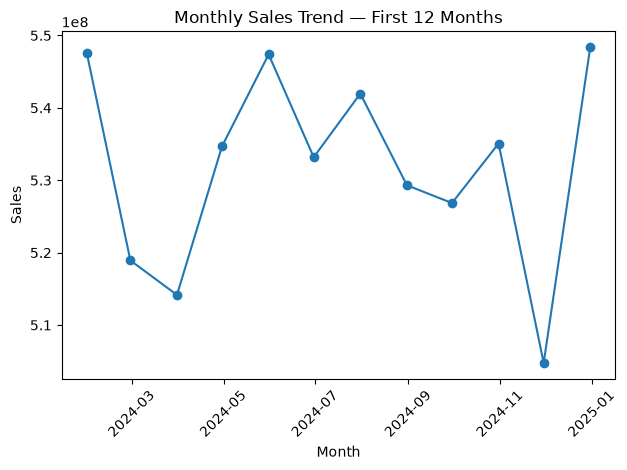

In [13]:
monthly_sales = (
    df.set_index("Order_Date")
      .resample("M")
      .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
)

monthly_sales_12 = monthly_sales.head(12)

plt.plot(
    monthly_sales_12.index,
    monthly_sales_12["Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend — First 12 Months")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 1],
    labels=["No discount", "0–10%", "10–20%", "20–30%", "30%+"]
)

discount_analysis = (
    df.groupby("Discount_Band", observed=True)
      .agg(
          Sales=("Sales", "sum"),
          Profit=("Profit", "sum"),
          Orders=("Order_ID", "nunique")
      )
)

discount_analysis["Profit_Margin_%"] = (
    discount_analysis["Profit"] / discount_analysis["Sales"] * 100
).round(2)

print("\nDISCOUNT ANALYSIS")
print(discount_analysis.round(2))


DISCOUNT ANALYSIS
                      Sales        Profit  Orders  Profit_Margin_%
Discount_Band                                                     
No discount    4.377160e+09  1.441387e+09   31626            32.93
0–10%          5.770675e+09  1.885264e+09   45145            32.67
10–20%         2.234507e+09  7.245191e+08   19212            32.42
20–30%         4.233481e+08  1.368123e+08    4017            32.32


In [15]:
df["Delivery_Days"] = (
    df["Delivery_Date"] - df["Order_Date"]
).dt.days

print("\nDELIVERY TIME")
print(df["Delivery_Days"].describe().round(2))


DELIVERY TIME
count    100000.00
mean          5.89
std           3.47
min           0.00
25%           3.00
50%           5.00
75%           9.00
max          12.00
Name: Delivery_Days, dtype: float64


In [16]:
loss_orders = df[df["Profit"] < 0]

print("\nLOSS-MAKING TRANSACTIONS")
print("Number of rows with negative profit:", len(loss_orders))
print(
    "Percentage of rows:",
    round(len(loss_orders) / len(df) * 100, 2), "%"
)
print("Sales on loss-making rows:", round(loss_orders["Sales"].sum(), 2))



LOSS-MAKING TRANSACTIONS
Number of rows with negative profit: 4059
Percentage of rows: 4.06 %
Sales on loss-making rows: 46730550.16
